## Parkinson Disease Detection -  Baseline implementation

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


## Settingup the reproducibiltiy configuration

In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

np.random.seed(RANDOM_STATE)

print("Random state:", RANDOM_STATE)
print("Test size:", TEST_SIZE)

Random state: 42
Test size: 0.2


## Load the Dataset

In [3]:
from google.colab import files

uploaded = files.upload()

Saving parkinsons.data to parkinsons.data


In [4]:
DATA_PATH = "parkinsons.data"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (195, 24)


## Display the first rows

In [5]:
df.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


## Inspect the Columns

In [6]:
print("Columns in dataset:\n")

for index, column in enumerate(df.columns, start=1):
    print(f"{index:02d}. {column}")

Columns in dataset:

01. name
02. MDVP:Fo(Hz)
03. MDVP:Fhi(Hz)
04. MDVP:Flo(Hz)
05. MDVP:Jitter(%)
06. MDVP:Jitter(Abs)
07. MDVP:RAP
08. MDVP:PPQ
09. Jitter:DDP
10. MDVP:Shimmer
11. MDVP:Shimmer(dB)
12. Shimmer:APQ3
13. Shimmer:APQ5
14. MDVP:APQ
15. Shimmer:DDA
16. NHR
17. HNR
18. status
19. RPDE
20. DFA
21. spread1
22. spread2
23. D2
24. PPE


## Checking the dataset quality

In [7]:
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["status"].value_counts())

print("\nClass percentages:")
print(df["status"].value_counts(normalize=True) * 100)

Dataset shape: (195, 24)
Total missing values: 0
Duplicate rows: 0

Class distribution:
status
1    147
0     48
Name: count, dtype: int64

Class percentages:
status
1    75.384615
0    24.615385
Name: proportion, dtype: float64


## Defining the Predictors and targets

In [8]:
X = df.drop(columns=["name", "status"])
y = df["status"]

print("Predictor matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumber of predictive features:", X.shape[1])
print("Target values:", sorted(y.unique()))

Predictor matrix shape: (195, 22)
Target shape: (195,)

Number of predictive features: 22
Target values: [np.int64(0), np.int64(1)]


## Check the class labels

In [9]:
print("Target definition:")
print("0 = Healthy")
print("1 = Parkinson's Disease")

print("\nCounts:")
print(y.value_counts().rename(index={0: "Healthy", 1: "Parkinson's Disease"}))

Target definition:
0 = Healthy
1 = Parkinson's Disease

Counts:
status
Parkinson's Disease    147
Healthy                 48
Name: count, dtype: int64


## 80:20 train test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training observations: 156
Testing observations: 39

Training class distribution:
status
1    118
0     38
Name: count, dtype: int64

Testing class distribution:
status
1    29
0    10
Name: count, dtype: int64


## Verify the train/test seperation

In [11]:
assert len(X_train) + len(X_test) == len(df)
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("Train/test checks passed.")

Train/test checks passed.


## Creating the baseline pipeline

In [12]:
baseline_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    )
])

print(baseline_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=5000, random_state=42))])


## Train the baseline model

In [13]:
baseline_pipeline.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


## Generating the predictors

In [14]:
y_pred = baseline_pipeline.predict(X_test)

y_probability = baseline_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred))

Predictions generated successfully.
Number of predictions: 39


## Calculate the baseline metrics

In [15]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

specificity = tn / (tn + fp)

baseline_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "F1-score",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        balanced_accuracy,
        roc_auc
    ]
})

baseline_metrics["Percentage"] = baseline_metrics["Score"] * 100

baseline_metrics.round(4)

,Metric,Score,Percentage
0,Accuracy,0.9231,92.3077
1,Precision,0.9333,93.3333
2,Recall / Sensitivity,0.9655,96.5517
3,Specificity,0.8000,80.0000
4,F1-score,0.9492,94.9153
5,Balanced Accuracy,0.8828,88.2759
6,ROC-AUC,0.9241,92.4138


## Classification report

In [16]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Healthy", "Parkinson's Disease"],
        digits=4
    )
)

                     precision    recall  f1-score   support

            Healthy     0.8889    0.8000    0.8421        10
Parkinson's Disease     0.9333    0.9655    0.9492        29

           accuracy                         0.9231        39
          macro avg     0.9111    0.8828    0.8956        39
       weighted avg     0.9219    0.9231    0.9217        39



## Display the confusion matrix

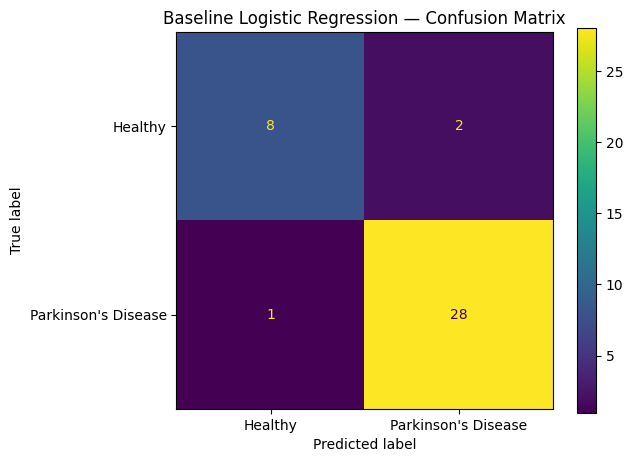

In [17]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Parkinson's Disease"]
)

display.plot()
plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

## ROC curve

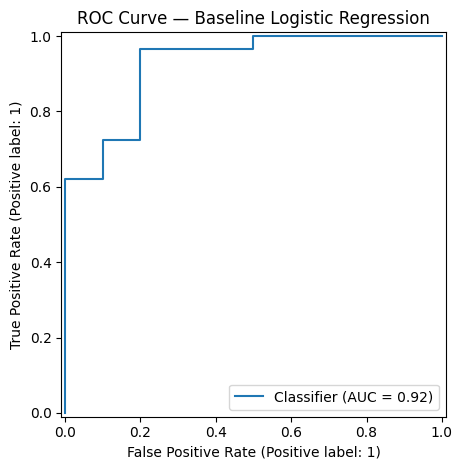

In [18]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.title("ROC Curve — Baseline Logistic Regression")
plt.tight_layout()
plt.show()

## Creating the cross-validation strategy

In [19]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cross-validation strategy created.")
print("Number of folds:", cv_strategy.get_n_splits())

Cross-validation strategy created.
Number of folds: 5


## Define the hyperparameter search

In [20]:
parameter_space = {
    "classifier__C": [
        0.001,
        0.01,
        0.05,
        0.1,
        0.5,
        1,
        2,
        5,
        10,
        50
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

print("Hyperparameter search space:")
print(parameter_space)

Hyperparameter search space:
{'classifier__C': [0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10, 50], 'classifier__class_weight': [None, 'balanced']}


## Configure the RandomizedSearchCV

In [21]:
random_search = RandomizedSearchCV(
    estimator=baseline_pipeline,
    param_distributions=parameter_space,
    n_iter=10,
    scoring="balanced_accuracy",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    verbose=1
)

print("RandomizedSearchCV configured successfully.")

RandomizedSearchCV configured successfully.


## Run the hyperparameter tuning

In [22]:
random_search.fit(X_train, y_train)

print("\nHyperparameter tuning completed.")

print("\nBest parameters:")
print(random_search.best_params_)

print(
    "\nBest mean cross-validation balanced accuracy:",
    round(random_search.best_score_, 4)
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits

Hyperparameter tuning completed.

Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__C': 5}

Best mean cross-validation balanced accuracy: 0.8263


## Obtaining the best model

In [23]:
best_model = random_search.best_estimator_

print("Best model:")
print(best_model)

Best model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(C=5, class_weight='balanced', max_iter=5000,
                                    random_state=42))])


## Evaluating the tuned model on test set

In [24]:
tuned_pred = best_model.predict(X_test)

tuned_probability = best_model.predict_proba(X_test)[:, 1]

tuned_accuracy = accuracy_score(y_test, tuned_pred)
tuned_precision = precision_score(y_test, tuned_pred)
tuned_recall = recall_score(y_test, tuned_pred)
tuned_f1 = f1_score(y_test, tuned_pred)
tuned_balanced_accuracy = balanced_accuracy_score(
    y_test,
    tuned_pred
)
tuned_roc_auc = roc_auc_score(
    y_test,
    tuned_probability
)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    tuned_pred
).ravel()

tuned_specificity = tn / (tn + fp)

tuned_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "F1-score",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Score": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_specificity,
        tuned_f1,
        tuned_balanced_accuracy,
        tuned_roc_auc
    ]
})

tuned_metrics["Percentage"] = tuned_metrics["Score"] * 100

tuned_metrics.round(4)

,Metric,Score,Percentage
0,Accuracy,0.7949,79.4872
1,Precision,0.9200,92.0000
2,Recall / Sensitivity,0.7931,79.3103
3,Specificity,0.8000,80.0000
4,F1-score,0.8519,85.1852
5,Balanced Accuracy,0.7966,79.6552
6,ROC-AUC,0.9276,92.7586


## Tuned model confusion matrix

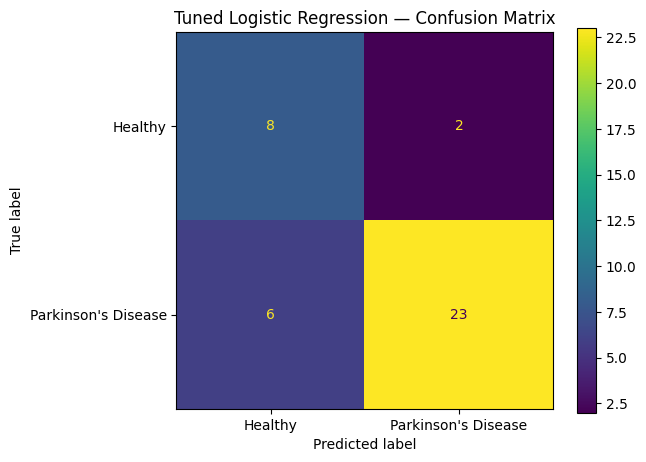

In [25]:
cm_tuned = confusion_matrix(
    y_test,
    tuned_pred
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Healthy", "Parkinson's Disease"]
)

display.plot()
plt.title("Tuned Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

## Comparing the untuned and tuned logistic Regression

In [26]:

model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Specificity",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Baseline Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1,
        specificity,
        balanced_accuracy,
        roc_auc
    ],
    "Tuned Logistic Regression": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_specificity,
        tuned_balanced_accuracy,
        tuned_roc_auc
    ]
})

model_comparison.iloc[:, 1:] *= 100

model_comparison.round(2)

,Metric,Baseline Logistic Regression,Tuned Logistic Regression
0,Accuracy,92.31,79.49
1,Precision,93.33,92.00
2,Recall,96.55,79.31
3,F1-score,94.92,85.19
4,Specificity,80.00,80.00
5,Balanced Accuracy,88.28,79.66
6,ROC-AUC,92.41,92.76


## Paper Results

In [27]:
comparison_with_paper = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Untuned Logistic Regression": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ],
    "Tuned Logistic Regression": [
        tuned_accuracy * 100,
        tuned_precision * 100,
        tuned_recall * 100,
        tuned_f1 * 100
    ],
    "Paper FNN": [
        99.11,
        99.96,
        98.78,
        99.23
    ]
})

comparison_with_paper.round(2)

,Metric,Untuned Logistic Regression,Tuned Logistic Regression,Paper FNN
0,Accuracy,92.31,79.49,99.11
1,Precision,93.33,92.00,99.96
2,Recall,96.55,79.31,98.78
3,F1-score,94.92,85.19,99.23


## calculate the differences from the paper

In [28]:
comparison_with_paper["Difference"] = (
    comparison_with_paper["Untuned Logistic Regression"]
    - comparison_with_paper["Paper FNN"]
)

comparison_with_paper.round(2)

,Metric,Untuned Logistic Regression,Tuned Logistic Regression,Paper FNN,Difference
0,Accuracy,92.31,79.49,99.11,-6.80
1,Precision,93.33,92.00,99.96,-6.63
2,Recall,96.55,79.31,98.78,-2.23
3,F1-score,94.92,85.19,99.23,-4.31


## Plot the comparison against the paper

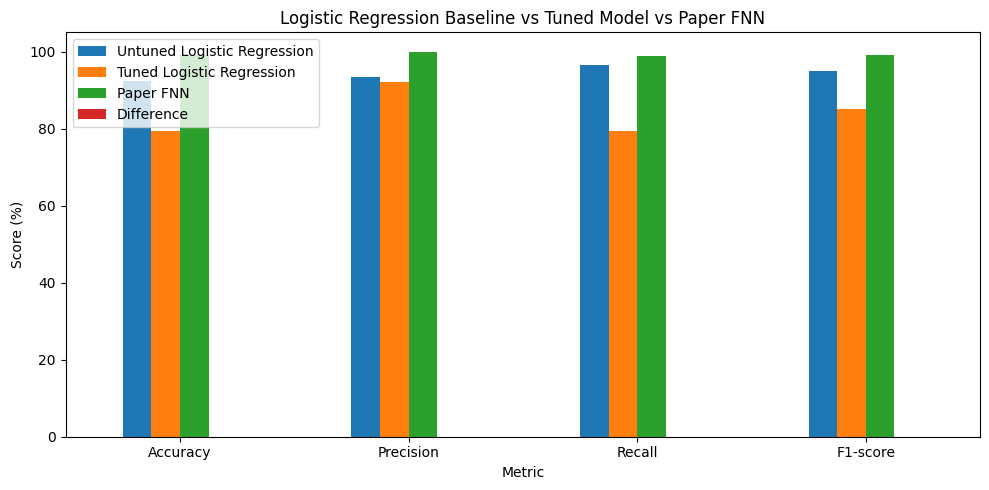

In [29]:
comparison_plot = comparison_with_paper.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Score (%)")
plt.title("Logistic Regression Baseline vs Tuned Model vs Paper FNN")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

## Important methodological warning

In [30]:
print(
    """
    Important Comparison Limitation

  the logistic regrssion baseline uses a 80:20 train test split with random_state = 42. so the research paper reports an 80:20 split for its strongest results, but it does not clearly establish whether the recordings from the same participant were prevented from the appearing across the training and testing sets.
  so, the numerical comparison with the paper should be interpreted as a comparison with reported performance, not as a proof that the differences is caused only the choice of the machine learning algorithm
  """
)


    Important Comparison Limitation

  the logistic regrssion baseline uses a 80:20 train test split with random_state = 42. so the research paper reports an 80:20 split for its strongest results, but it does not clearly establish whether the recordings from the same participant were prevented from the appearing across the training and testing sets.
  so, the numerical comparison with the paper should be interpreted as a comparison with reported performance, not as a proof that the differences is caused only the choice of the machine learning algorithm
  


## Save the results

In [31]:
baseline_metrics.to_csv(
    "baseline_metrics.csv",
    index=False
)

tuned_metrics.to_csv(
    "tuned_metrics.csv",
    index=False
)

comparison_with_paper.to_csv(
    "comparison_with_paper.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


## Final Implementation summary

In [32]:
print("PARKINSON'S DISEASE BASELINE IMPLEMENTATION")


print("\nDataset:")
print(f"Observations: {len(df)}")
print(f"Predictive features: {X.shape[1]}")
print("Positive class: Parkinson's Disease (status = 1)")

print("\nSplit:")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Random state: {RANDOM_STATE}")

print("\nUntuned Logistic Regression:")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-score:  {f1 * 100:.2f}%")

print("\nTuned Logistic Regression:")
print(f"Accuracy:  {tuned_accuracy * 100:.2f}%")
print(f"Precision: {tuned_precision * 100:.2f}%")
print(f"Recall:    {tuned_recall * 100:.2f}%")
print(f"F1-score:  {tuned_f1 * 100:.2f}%")

print("\nPaper's Reported FNN:")
print("Accuracy:  99.11%")
print("Precision: 99.96%")
print("Recall:    98.78%")
print("F1-score:  99.23%")

print("\nBest Logistic Regression parameters:")
print(random_search.best_params_)


PARKINSON'S DISEASE BASELINE IMPLEMENTATION

Dataset:
Observations: 195
Predictive features: 22
Positive class: Parkinson's Disease (status = 1)

Split:
Training samples: 156
Testing samples: 39
Random state: 42

Untuned Logistic Regression:
Accuracy:  92.31%
Precision: 93.33%
Recall:    96.55%
F1-score:  94.92%

Tuned Logistic Regression:
Accuracy:  79.49%
Precision: 92.00%
Recall:    79.31%
F1-score:  85.19%

Paper's Reported FNN:
Accuracy:  99.11%
Precision: 99.96%
Recall:    98.78%
F1-score:  99.23%

Best Logistic Regression parameters:
{'classifier__class_weight': 'balanced', 'classifier__C': 5}


## Random Forest

In [33]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully.")

Random Forest imported successfully.


## Create the baseline Random Forest

In [34]:
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

print(rf_baseline)

RandomForestClassifier(random_state=42)


## Train the baseline Random Forest

In [35]:
rf_baseline.fit(X_train, y_train)

print("Baseline Random Forest trained successfully.")

Baseline Random Forest trained successfully.


## Generate predictions

In [36]:
rf_pred = rf_baseline.predict(X_test)
rf_probability = rf_baseline.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully.")
print("Number of predictions:", len(rf_pred))

Random Forest predictions generated successfully.
Number of predictions: 39


## Calculate Random Forest baseline metrics

In [37]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_balanced_accuracy = balanced_accuracy_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_probability)

rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
    y_test,
    rf_pred
).ravel()

rf_specificity = rf_tn / (rf_tn + rf_fp)

rf_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "F1-score",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Score": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_specificity,
        rf_f1,
        rf_balanced_accuracy,
        rf_roc_auc
    ]
})

rf_metrics["Percentage"] = rf_metrics["Score"] * 100

rf_metrics.round(4)

,Metric,Score,Percentage
0,Accuracy,0.9231,92.3077
1,Precision,0.9333,93.3333
2,Recall / Sensitivity,0.9655,96.5517
3,Specificity,0.8000,80.0000
4,F1-score,0.9492,94.9153
5,Balanced Accuracy,0.8828,88.2759
6,ROC-AUC,0.9621,96.2069


## Classification report

In [38]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Healthy", "Parkinson's Disease"],
        digits=4
    )
)

                     precision    recall  f1-score   support

            Healthy     0.8889    0.8000    0.8421        10
Parkinson's Disease     0.9333    0.9655    0.9492        29

           accuracy                         0.9231        39
          macro avg     0.9111    0.8828    0.8956        39
       weighted avg     0.9219    0.9231    0.9217        39



## Random Forest Confusion matrix

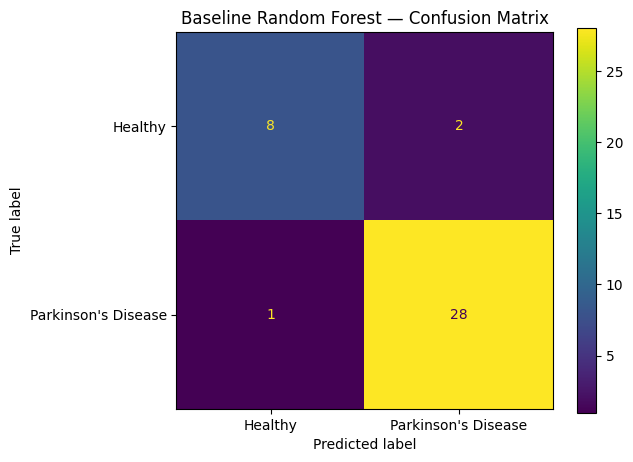

In [39]:
rf_cm = confusion_matrix(y_test, rf_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Healthy", "Parkinson's Disease"]
)

display.plot()
plt.title("Baseline Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

## ROC Curve

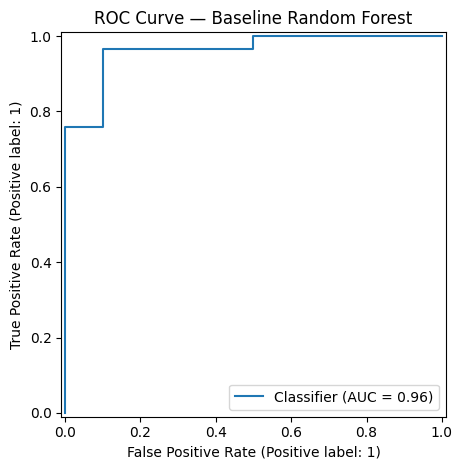

In [40]:
RocCurveDisplay.from_predictions(
    y_test,
    rf_probability
)

plt.title("ROC Curve — Baseline Random Forest")
plt.tight_layout()
plt.show()

## Random Forest Hyperparameter Tuning

In [41]:
rf_parameter_space = {
    "n_estimators": [50, 100, 200, 300, 500],
    "max_depth": [None, 3, 5, 8, 10],
    "min_samples_split": [2, 4, 6, 8],
    "min_samples_leaf": [1, 2, 3, 4],
    "max_features": ["sqrt", "log2", None],
    "class_weight": [None, "balanced"]
}

print("Random Forest hyperparameter search space created.")

Random Forest hyperparameter search space created.


## Configure RandomizedSearchCV

In [42]:
rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE
    ),
    param_distributions=rf_parameter_space,
    n_iter=20,
    scoring="balanced_accuracy",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    verbose=1
)

print("Random Forest RandomizedSearchCV configured successfully.")

Random Forest RandomizedSearchCV configured successfully.


## Run the Random Forest tuning

In [43]:
rf_random_search.fit(X_train, y_train)

print("\nRandom Forest hyperparameter tuning completed.")

print("\nBest parameters:")
print(rf_random_search.best_params_)

print(
    "\nBest mean cross-validation balanced accuracy:",
    round(rf_random_search.best_score_, 4)
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Random Forest hyperparameter tuning completed.

Best parameters:
{'n_estimators': 100, 'min_samples_split': 6, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 10, 'class_weight': 'balanced'}

Best mean cross-validation balanced accuracy: 0.8566


## Get the tuned Random Forest

In [44]:
best_rf_model = rf_random_search.best_estimator_

print("Best Random Forest model:")
print(best_rf_model)

Best Random Forest model:
RandomForestClassifier(class_weight='balanced', max_depth=10, max_features=None,
                       min_samples_leaf=4, min_samples_split=6,
                       random_state=42)


## Evaluate tuned Random Forest

In [45]:
rf_tuned_pred = best_rf_model.predict(X_test)

rf_tuned_probability = best_rf_model.predict_proba(
    X_test
)[:, 1]

rf_tuned_accuracy = accuracy_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_precision = precision_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_recall = recall_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_f1 = f1_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_balanced_accuracy = balanced_accuracy_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_roc_auc = roc_auc_score(
    y_test,
    rf_tuned_probability
)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    rf_tuned_pred
).ravel()

rf_tuned_specificity = tn / (tn + fp)

rf_tuned_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "F1-score",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Score": [
        rf_tuned_accuracy,
        rf_tuned_precision,
        rf_tuned_recall,
        rf_tuned_specificity,
        rf_tuned_f1,
        rf_tuned_balanced_accuracy,
        rf_tuned_roc_auc
    ]
})

rf_tuned_metrics["Percentage"] = (
    rf_tuned_metrics["Score"] * 100
)

rf_tuned_metrics.round(4)

,Metric,Score,Percentage
0,Accuracy,0.9231,92.3077
1,Precision,0.9333,93.3333
2,Recall / Sensitivity,0.9655,96.5517
3,Specificity,0.8000,80.0000
4,F1-score,0.9492,94.9153
5,Balanced Accuracy,0.8828,88.2759
6,ROC-AUC,0.9552,95.5172


## Tuned Random Forest Confusion matrix

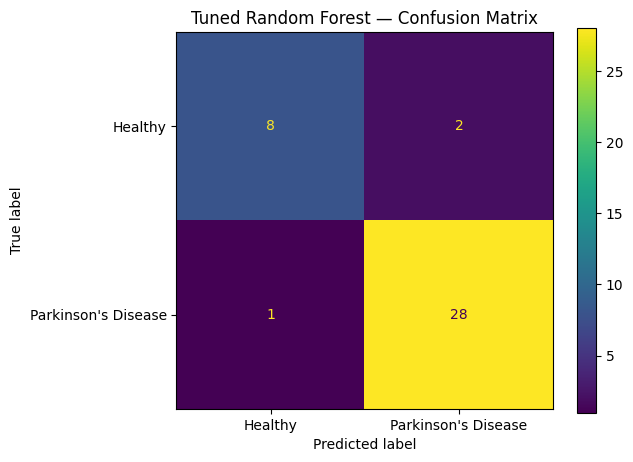

In [46]:
rf_tuned_cm = confusion_matrix(
    y_test,
    rf_tuned_pred
)

display = ConfusionMatrixDisplay(
    confusion_matrix=rf_tuned_cm,
    display_labels=["Healthy", "Parkinson's Disease"]
)

display.plot()
plt.title("Tuned Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

## Comapre the Logistic Regression VS Random Forest

In [47]:
final_comparison = pd.DataFrame({
    "Model": [
        "Untuned Logistic Regression",
        "Tuned Logistic Regression",
        "Untuned Random Forest",
        "Tuned Random Forest",
        "Paper FNN"
    ],
    "Accuracy": [
        accuracy * 100,
        tuned_accuracy * 100,
        rf_accuracy * 100,
        rf_tuned_accuracy * 100,
        99.11
    ],
    "Precision": [
        precision * 100,
        tuned_precision * 100,
        rf_precision * 100,
        rf_tuned_precision * 100,
        99.96
    ],
    "Recall": [
        recall * 100,
        tuned_recall * 100,
        rf_recall * 100,
        rf_tuned_recall * 100,
        98.78
    ],
    "F1-score": [
        f1 * 100,
        tuned_f1 * 100,
        rf_f1 * 100,
        rf_tuned_f1 * 100,
        99.23
    ]
})

final_comparison.round(2)

,Model,Accuracy,Precision,Recall,F1-score
0,Untuned Logistic Regression,92.31,93.33,96.55,94.92
1,Tuned Logistic Regression,79.49,92.00,79.31,85.19
2,Untuned Random Forest,92.31,93.33,96.55,94.92
3,Tuned Random Forest,92.31,93.33,96.55,94.92
4,Paper FNN,99.11,99.96,98.78,99.23


## Plot all models against the paper

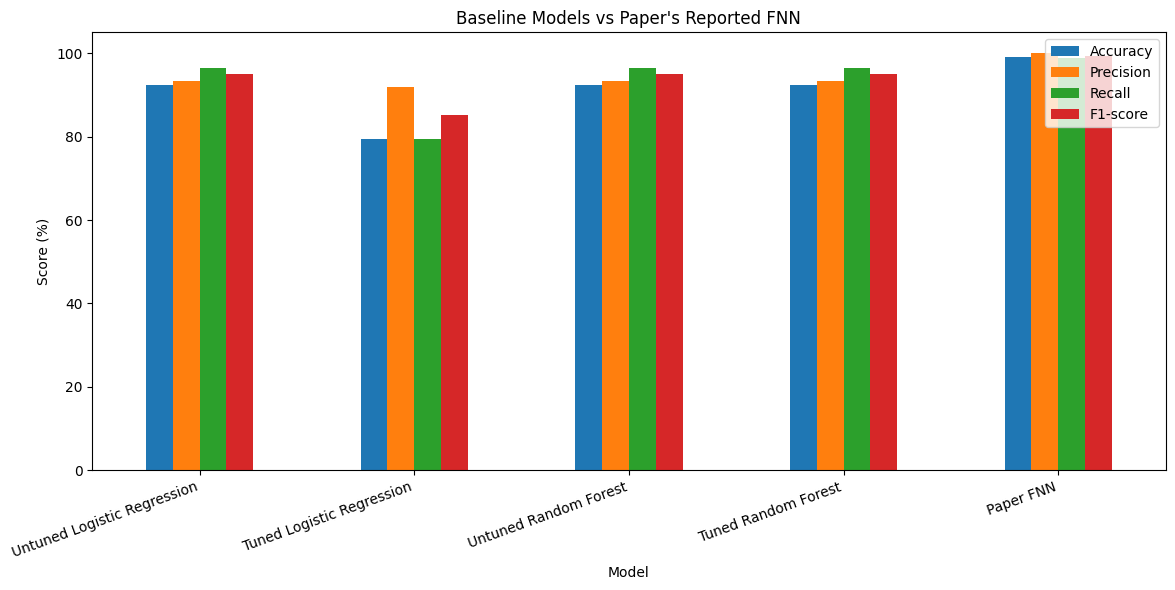

In [48]:
plot_data = final_comparison.set_index("Model")

plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylabel("Score (%)")
plt.title("Baseline Models vs Paper's Reported FNN")
plt.ylim(0, 105)
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

## Printed final summary

In [49]:
print("MODEL COMPARISON SUMMARY")

print("\nUntuned Logistic Regression")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"F1-score: {f1 * 100:.2f}%")

print("\nTuned Logistic Regression")
print(f"Accuracy: {tuned_accuracy * 100:.2f}%")
print(f"F1-score: {tuned_f1 * 100:.2f}%")

print("\nUntuned Random Forest")
print(f"Accuracy: {rf_accuracy * 100:.2f}%")
print(f"F1-score: {rf_f1 * 100:.2f}%")

print("\nTuned Random Forest")
print(f"Accuracy: {rf_tuned_accuracy * 100:.2f}%")
print(f"F1-score: {rf_tuned_f1 * 100:.2f}%")

print("\nPaper FNN")
print("Accuracy: 99.11%")
print("F1-score: 99.23%")

print("\nBest Random Forest parameters:")
print(rf_random_search.best_params_)

MODEL COMPARISON SUMMARY

Untuned Logistic Regression
Accuracy: 92.31%
F1-score: 94.92%

Tuned Logistic Regression
Accuracy: 79.49%
F1-score: 85.19%

Untuned Random Forest
Accuracy: 92.31%
F1-score: 94.92%

Tuned Random Forest
Accuracy: 92.31%
F1-score: 94.92%

Paper FNN
Accuracy: 99.11%
F1-score: 99.23%

Best Random Forest parameters:
{'n_estimators': 100, 'min_samples_split': 6, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 10, 'class_weight': 'balanced'}
